<a href="https://colab.research.google.com/github/fatihludyaryasatya/tugas-citra-digital/blob/main/tugas_citra_digital.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Install library

!pip -q install pillow-heif

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 55.4 MB/s eta 0:00:00


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Upload gambar

from google.colab import files
up = files.upload()
nama_file = list(up.keys())[0]
print("File:", nama_file)

Saving gambar.jpg.HEIC to gambar.jpg.HEIC
File: gambar.jpg.HEIC


# 1. Gambar sebagai Array Angka
Gambar dibaca dengan Pillow lalu diubah menjadi array NumPy. Setiap piksel
berisi 3 angka (Red, Green, Blue) dengan rentang 0-255. Shape array
(tinggi, lebar, 3) menunjukkan bahwa gambar hanyalah matriks angka.

In [5]:
# Buka gambar dan buktikan bahwa ia berupa angka

import numpy as np
from PIL import Image
import pillow_heif
pillow_heif.register_heif_opener()

img = Image.open(nama_file).convert("RGB")
arr = np.array(img)

print("Tipe data      :", type(arr))
print("Shape (T,L,Ch) :", arr.shape)
print("dtype          :", arr.dtype)
print("Nilai min/max  :", arr.min(), "/", arr.max())
print("Total piksel   :", arr.shape[0] * arr.shape[1])
print("Total angka    :", arr.size)
print("\nPiksel kiri-atas (5x5), format [R, G, B]:")
print(arr[:5, :5])

Tipe data      : <class 'numpy.ndarray'>
Shape (T,L,Ch) : (4032, 3024, 3)
dtype          : uint8
Nilai min/max  : 0 / 255
Total piksel   : 12192768
Total angka    : 36578304

Piksel kiri-atas (5x5), format [R, G, B]:
[[[ 58  62  38]
  [112 116  92]
  [154 158 133]
  [135 139 114]
  [ 73  77  52]]

 [[110 114  90]
  [124 128 104]
  [153 157 132]
  [127 131 106]
  [ 72  76  51]]

 [[158 163 139]
  [142 147 123]
  [135 144 117]
  [103 112  85]
  [ 49  58  31]]

 [[134 139 115]
  [143 148 124]
  [118 127 100]
  [ 67  76  49]
  [ 30  39  12]]

 [[ 37  47  21]
  [ 40  50  24]
  [ 46  59  31]
  [  7  20   0]
  [ 14  27   0]]]


# 2. Zoom ke Level Piksel
Potongan 8x8 piksel diperbesar agar terlihat bahwa gambar tersusun dari
kotak-kotak kecil, dan setiap kotak memiliki nilai intensitas tertentu.
Semakin mendekati 255 semakin terang, semakin mendekati 0 semakin gelap.

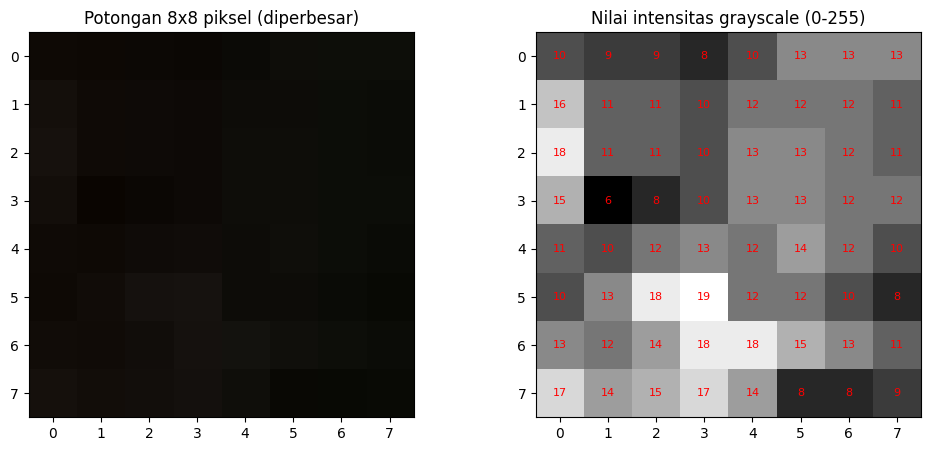

[[[14  9  5]
  [13  8  4]
  [12  8  5]
  [11  7  4]
  [11 10  6]
  [14 13  9]
  [13 14  9]
  [13 14  9]]

 [[20 15 11]
  [15 10  6]
  [14 10  7]
  [13  9  6]
  [13 12  8]
  [13 12  8]
  [12 13  8]
  [11 12  7]]

 [[22 17 13]
  [15 10  6]
  [14 10  7]
  [13  9  6]
  [14 13  9]
  [14 13  9]
  [12 13  8]
  [11 12  7]]

 [[19 14 10]
  [10  5  1]
  [11  7  4]
  [13  9  6]
  [14 13  9]
  [14 13  9]
  [12 13  8]
  [12 13  8]]

 [[15 10  6]
  [14  9  5]
  [15 11  8]
  [16 12  9]
  [13 12  8]
  [15 14 10]
  [12 13  8]
  [10 11  6]]

 [[14  9  5]
  [17 12  8]
  [21 17 14]
  [22 18 15]
  [13 12  8]
  [13 12  8]
  [10 11  6]
  [ 8  9  4]]

 [[17 12  8]
  [16 11  7]
  [17 13 10]
  [21 17 14]
  [19 18 14]
  [16 15 11]
  [13 14  9]
  [11 12  7]]

 [[21 16 12]
  [18 13  9]
  [18 14 11]
  [20 16 13]
  [15 14 10]
  [ 9  8  4]
  [ 8  9  4]
  [ 9 10  5]]]


In [6]:
# Perbesar 8x8 piksel, tampilkan gambar dan angkanya

import matplotlib.pyplot as plt

y, x = arr.shape[0] // 2, arr.shape[1] // 2   # titik tengah
patch = arr[y:y+8, x:x+8]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(patch, interpolation="nearest")
ax[0].set_title("Potongan 8x8 piksel (diperbesar)")
gray_patch = np.array(Image.fromarray(patch).convert("L"))
ax[1].imshow(gray_patch, cmap="gray", interpolation="nearest")
for i in range(8):
    for j in range(8):
        ax[1].text(j, i, gray_patch[i, j], ha="center", va="center",
                   color="red", fontsize=8)
ax[1].set_title("Nilai intensitas grayscale (0-255)")
plt.show()
print(patch)

# 3. Kanal Warna
Gambar berwarna terdiri dari 3 matriks: Red, Green, Blue. Warna yang kita
lihat adalah gabungan ketiganya pada tiap piksel.

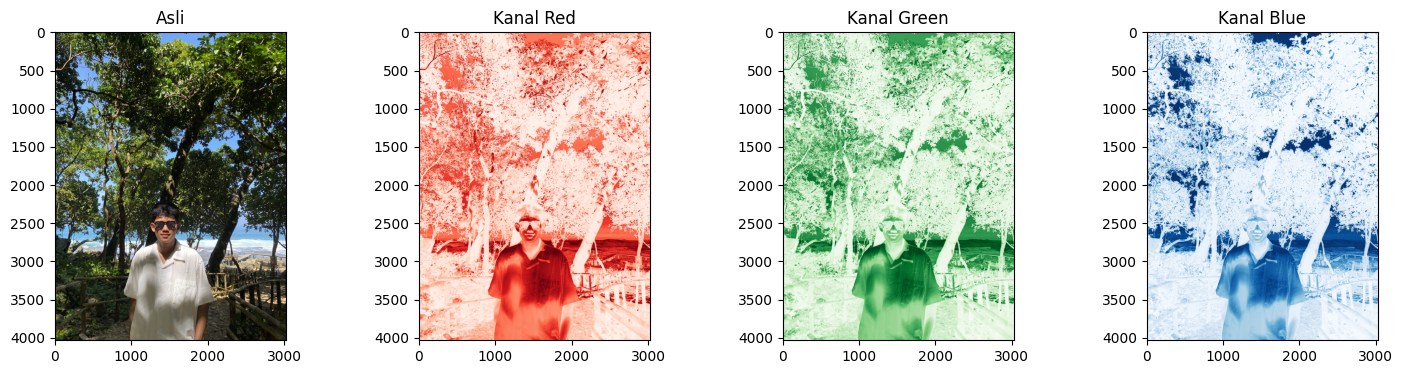

In [7]:
# Pisahkan kanal R, G, B

fig, ax = plt.subplots(1, 4, figsize=(18, 4))
ax[0].imshow(arr); ax[0].set_title("Asli")
for k, (nama, cmap) in enumerate([("Red","Reds"),("Green","Greens"),("Blue","Blues")]):
    ax[k+1].imshow(arr[:, :, k], cmap=cmap)
    ax[k+1].set_title(f"Kanal {nama}")
plt.show()

# 4. Grayscale dan Histogram
Grayscale dihitung dengan rumus 0.299R + 0.587G + 0.114B, sehingga 3 angka
per piksel menjadi 1 angka. Histogram menunjukkan sebaran jumlah piksel
pada tiap tingkat kecerahan.

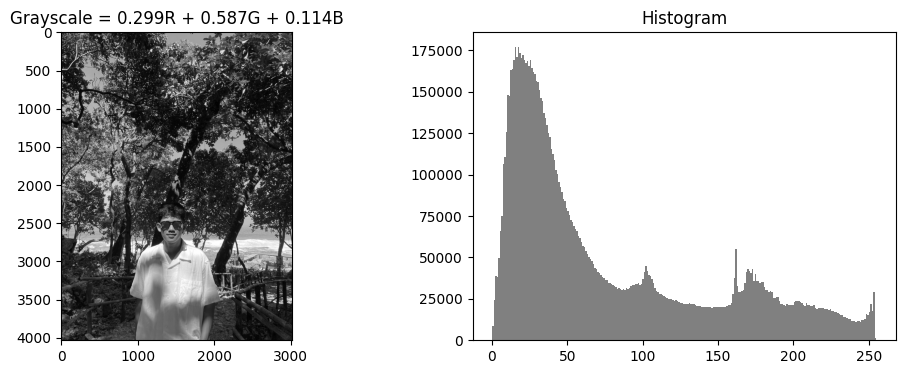

In [8]:
# Grayscale dari rumus dan histogram

gray = (0.299*arr[:,:,0] + 0.587*arr[:,:,1] + 0.114*arr[:,:,2]).astype(np.uint8)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(gray, cmap="gray"); ax[0].set_title("Grayscale = 0.299R + 0.587G + 0.114B")
ax[1].hist(gray.ravel(), bins=256, color="gray"); ax[1].set_title("Histogram")
plt.show()

# 5. Mengubah Angka = Mengubah Gambar
Sebagian nilai piksel diubah manual menjadi [255, 0, 0] (merah). Gambar ikut
berubah, membuktikan bahwa gambar sepenuhnya ditentukan oleh angka-angka ini.

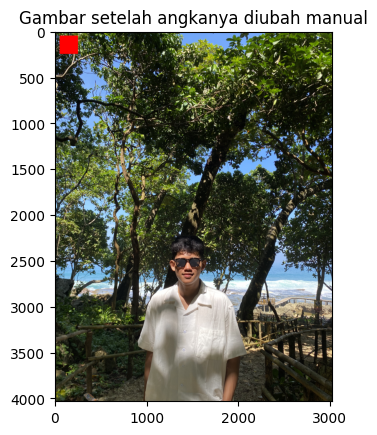

In [9]:
# Buktikan angka bisa diubah dan gambarnya ikut berubah

arr2 = arr.copy()
arr2[50:250, 50:250] = [255, 0, 0]      # ubah angka jadi merah
plt.imshow(arr2); plt.title("Gambar setelah angkanya diubah manual"); plt.show()

# Rekonstruksi dari angka murni
Image.fromarray(arr).save("hasil_rekonstruksi.png")

# 6. Metadata
Selain angka piksel, file gambar menyimpan metadata: format, ukuran, mode
warna, dan EXIF (misalnya model kamera dan waktu pengambilan). Data GPS
sengaja disembunyikan demi privasi karena repository bersifat public.

In [10]:
# Metadata (tanpa GPS)

import os
from PIL.ExifTags import TAGS

img_asli = Image.open(nama_file)
print("Format       :", img_asli.format)
print("Mode warna   :", img_asli.mode)
print("Ukuran (px)  :", img_asli.size)
print("Ukuran file  :", round(os.path.getsize(nama_file)/1024, 1), "KB")
print("Ukuran mentah:", round(arr.nbytes/1024, 1), "KB (tanpa kompresi)")

exif = img_asli.getexif()
print("\n=== EXIF ===")
for tag_id, val in exif.items():
    tag = TAGS.get(tag_id, tag_id)
    if tag == "GPSInfo":        # disembunyikan demi privasi
        continue
    print(f"{tag}: {val}")

Format       : HEIF
Mode warna   : RGB
Ukuran (px)  : (3024, 4032)
Ukuran file  : 3095.0 KB
Ukuran mentah: 35721.0 KB (tanpa kompresi)

=== EXIF ===
ResolutionUnit: 2
ExifOffset: 216
Make: Apple
Model: iPhone 11
Software: 18.7.1
Orientation: 1
DateTime: 2026:04:16 10:03:36
XResolution: 72.0
YResolution: 72.0
HostComputer: iPhone 11


In [11]:
# Simpan potongan piksel sebagai file angka

os.makedirs("output", exist_ok=True)
np.savetxt("output/gray_8x8.csv", gray_patch, fmt="%d", delimiter=",")
np.save("output/piksel_5x5.npy", arr[:5, :5])